# Analyzing Thematic Alignment in EMLP Conference Papers

This notebook analyzes the thematic alignment between papers published at EMLP(Empirical Methods in Natural Language Processing) and the conference's stated Aims&Scope, using sentence embedding and cosine similarity.

## Pipeline
1. Data collection via Semantic Scholar API
2. Text embedding using allenai-specter
3. Alignement score computation via cosine similarity
4. Results analysis and visualization

## 1. Installation
Install the required libraries:

In [1]:
!pip install requests pandas sentence-transformers matplotlib scikit-learn

## 2. Data Collection
We collect abstacts from EMLP papers using the Semantic Scholar API, filtering only papers published at the "Conference on Empirical Methods in Natural Language Processing" with a non-empty abstract.

In [2]:
import requests
import pandas as pd
import time
from dotenv import load_dotenv
import os
import json

load_dotenv()

if os.path.exists("../data/abstracts.json"):
    print("Data already collected, skipping...")
    with open("../data/abstracts.json", "r") as f:
        articoli_validi = json.load(f)
    print(f"Loaded {len(articoli_validi)} articles")
else:
    API_KEY = os.getenv("SEMANTIC_SCHOLAR_API_KEY")
    BASE_URL = "https://api.semanticscholar.org/graph/v1/paper/search"
    PARAMS = {
        "query": "EMNLP empirical methods natural language processing",
        "fields": "title,abstract,year,venue",
        "limit": 100
    }
    HEADERS = {"x-api-key": API_KEY}

    articoli_validi = []
    offset = 0

    while len(articoli_validi) < 1000:
        PARAMS["offset"] = offset
        response = requests.get(BASE_URL, headers=HEADERS, params=PARAMS)
        
        if response.status_code == 429:
            print("Too many requests, waiting 10 seconds...")
            time.sleep(10)
            continue
        
        data = response.json()
        if "data" not in data or len(data["data"]) == 0:
            break
        
        for articolo in data["data"]:
            venue = articolo.get("venue", "")
            abstract = articolo.get("abstract", None)
            year = articolo.get("year", None)
            
            if (venue == "Conference on Empirical Methods in Natural Language Processing" 
                and abstract is not None 
                and year is not None 
                and year >= 2019):
                articoli_validi.append({
                    "title": articolo.get("title", ""),
                    "abstract": abstract,
                    "year": year,
                    "venue": venue
                })
        
        offset += 100
        time.sleep(3)
        print(f"Offset: {offset} | Valid articles so far: {len(articoli_validi)}")

    print(f"Total articles collected: {len(articoli_validi)}")

    with open("../data/abstracts.json", "w") as f:
        json.dump(articoli_validi, f, indent=2)

    print("Saved to data/abstracts.json")

Data already collected, skipping...
Loaded 330 articles


## 3. Embedding generation
We use allenai-specter, a BERT-based model pre-trained on scientific papers, to generate dense vector representations of each abstract and the Aim&Scopes text. 

In [3]:
import json
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

if os.path.exists("../results/results.json"):
    print("Alignment scores already computed, skipping...")
    with open("../results/results.json", "r") as f:
        articoli = json.load(f)
else:
    model = SentenceTransformer('allenai-specter')

    with open("../data/aims_and_scope.txt", "r") as f:
        aims_and_scope = f.read()

    with open("../data/abstracts.json", "r") as f:
        articoli = json.load(f)

    print("Generating Aims & Scope embedding...")
    embedding_aims = model.encode(aims_and_scope)

    print("Generating abstract embeddings...")
    abstracts_testi = [articolo["abstract"] for articolo in articoli]
    embeddings_abstract = model.encode(abstracts_testi, show_progress_bar=True)

    np.save("../data/embedding_aims.npy", embedding_aims)
    np.save("../data/embeddings_abstract.npy", embeddings_abstract)
    print("Embeddings saved!")

    scores = cosine_similarity([embedding_aims], embeddings_abstract)[0]

    for i, articolo in enumerate(articoli):
        articolo["alignment_score"] = float(scores[i])

    with open("../results/results.json", "w") as f:
        json.dump(articoli, f, indent=2)

    print("Alignment scores saved to results/results.json")

Alignment scores already computed, skipping...


## 4. Alignement analysis
We compute cosine similarity between each abstract and the Aim&Scope embedding as alignement score.

In [4]:
%matplotlib inline
import json
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

with open("../results/results.json", "r") as f:
    articoli = json.load(f)

scores = np.array([a["alignment_score"] for a in articoli])
anni = [a["year"] for a in articoli]
titoli = [a["title"] for a in articoli]

print(f"Total articles: {len(articoli)}")
print(f"Mean score: {scores.mean():.4f}")
print(f"Std: {scores.std():.4f}")
print(f"Min: {scores.min():.4f}")
print(f"Max: {scores.max():.4f}")

Total articles: 330
Mean score: 0.7699
Std: 0.0509
Min: 0.6226
Max: 0.9184


### Distribution of alignment scores

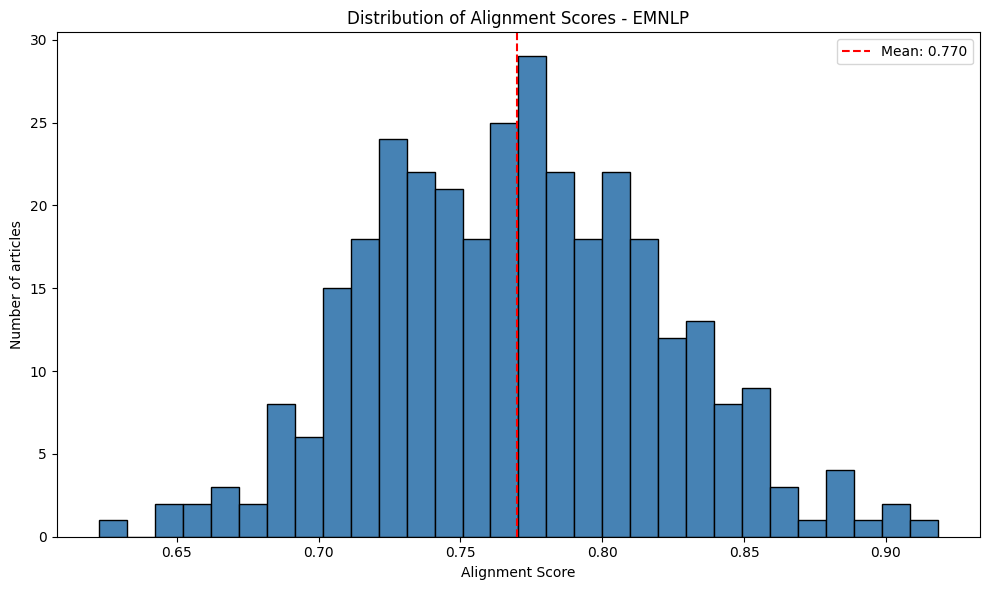

In [5]:
plt.figure(figsize=(10, 6))
plt.hist(scores, bins=30, color='steelblue', edgecolor='black')
plt.axvline(scores.mean(), color='red', linestyle='--', label=f'Mean: {scores.mean():.3f}')
plt.xlabel('Alignment Score')
plt.ylabel('Number of articles')
plt.title('Distribution of Alignment Scores - EMNLP')
plt.legend()
plt.tight_layout()
plt.savefig("../results/histogram.png")
plt.show()

### Temporal drift analysis

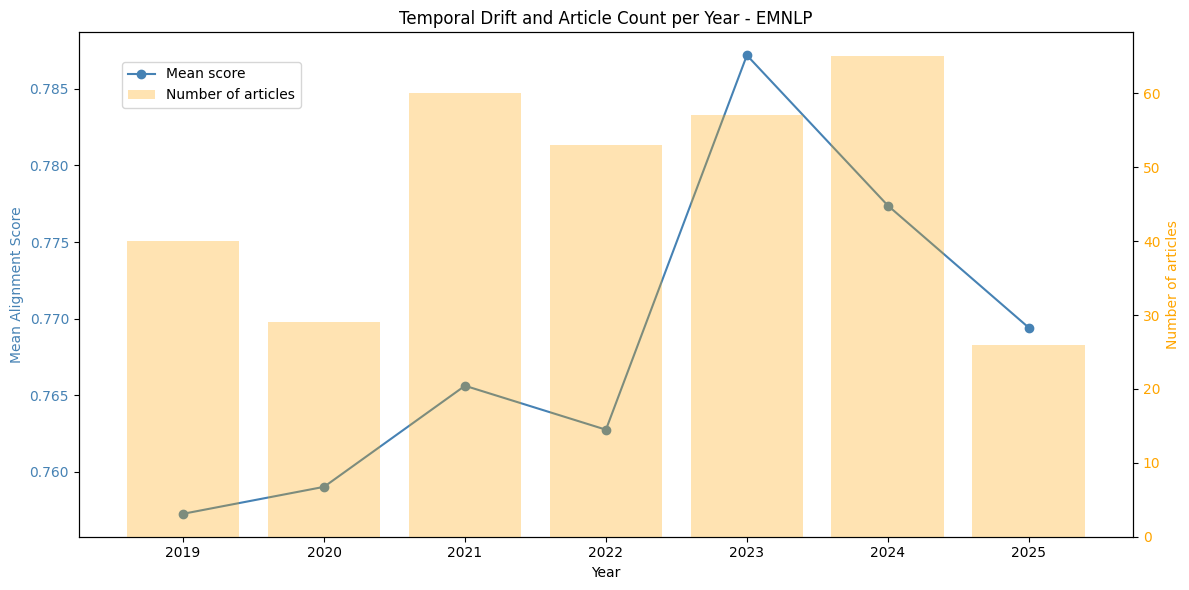

In [6]:
scores_per_anno = defaultdict(list)
for a in articoli:
    if a["year"]:
        scores_per_anno[a["year"]].append(a["alignment_score"])

anni_ordinati = sorted(scores_per_anno.keys())
medie_annuali = [np.mean(scores_per_anno[a]) for a in anni_ordinati]
conteggio_per_anno = [len(scores_per_anno[a]) for a in anni_ordinati]

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(anni_ordinati, medie_annuali, marker='o', color='steelblue', label='Mean score')
ax1.set_xlabel('Year')
ax1.set_ylabel('Mean Alignment Score', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')

ax2 = ax1.twinx()
ax2.bar(anni_ordinati, conteggio_per_anno, alpha=0.3, color='orange', label='Number of articles')
ax2.set_ylabel('Number of articles', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

plt.title('Temporal Drift and Article Count per Year - EMNLP')
fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.9))
plt.tight_layout()
plt.savefig("../results/drift_temporale_contestualizzato.png")
plt.show()

### Outlier analysis

Outliers are defined as papers with alignment score beyond ±2 standard deviations from the mean.

Low threshold: 0.6680
High threshold: 0.8718

Low outliers: 6
  Score: 0.6226 | Year: 2019 | A Boundary-aware Neural Model for Nested Named Entity Recogn
  Score: 0.6513 | Year: 2019 | Investigating Capsule Network and Semantic Feature on Hyperp
  Score: 0.6516 | Year: 2025 | Enhancing Large Language Model for Knowledge Graph Completio
  Score: 0.6575 | Year: 2021 | Deep Attention Diffusion Graph Neural Networks for Text Clas
  Score: 0.6595 | Year: 2022 | Face-Sensitive Image-to-Emotional-Text Cross-modal Translati
  Score: 0.6625 | Year: 2024 | Unifying Multimodal Retrieval via Document Screenshot Embedd

High outliers: 9
  Score: 0.9184 | Year: 2023 | We are Who We Cite: Bridges of Influence Between Natural Lan
  Score: 0.9076 | Year: 2021 | Narrative Theory for Computational Narrative Understanding
  Score: 0.9035 | Year: 2024 | How to Compute the Probability of a Word
  Score: 0.8957 | Year: 2024 | Understanding “Democratization” in NLP and ML Research
  Score: 0.8838 | Year: 2021

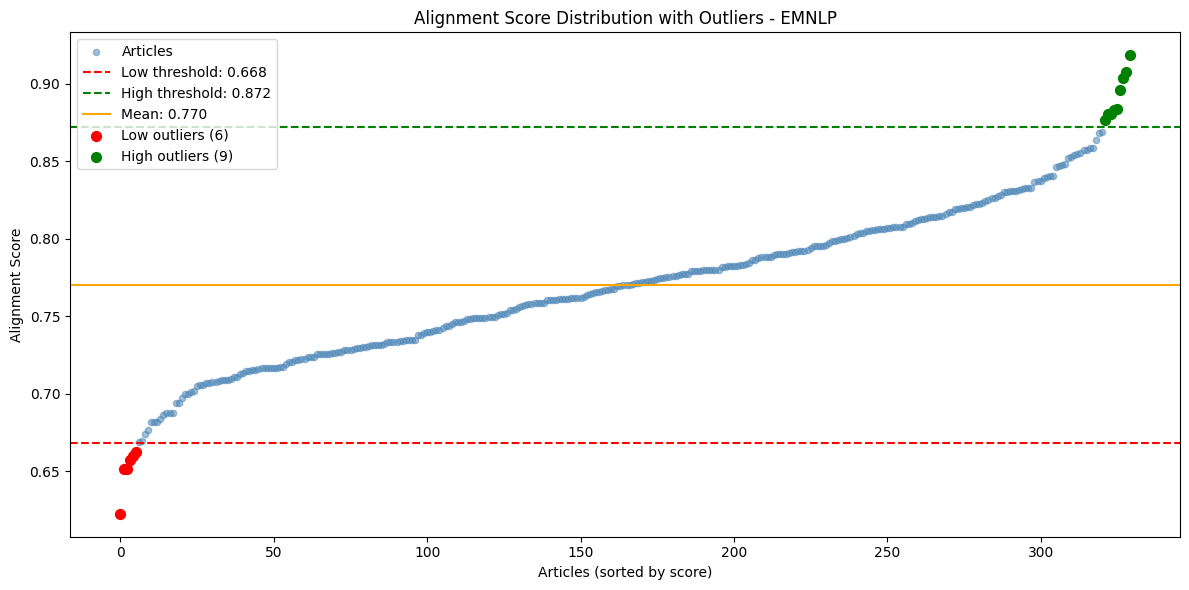

In [7]:
soglia_bassa = scores.mean() - 2*scores.std()
soglia_alta = scores.mean() + 2*scores.std()

outlier_bassi_list = [a for a in articoli if a["alignment_score"] < soglia_bassa]
outlier_alti_list = [a for a in articoli if a["alignment_score"] > soglia_alta]

print(f"Low threshold: {soglia_bassa:.4f}")
print(f"High threshold: {soglia_alta:.4f}")
print(f"\nLow outliers: {len(outlier_bassi_list)}")
for a in sorted(outlier_bassi_list, key=lambda x: x["alignment_score"]):
    print(f"  Score: {a['alignment_score']:.4f} | Year: {a['year']} | {a['title'][:60]}")

print(f"\nHigh outliers: {len(outlier_alti_list)}")
for a in sorted(outlier_alti_list, key=lambda x: x["alignment_score"], reverse=True):
    print(f"  Score: {a['alignment_score']:.4f} | Year: {a['year']} | {a['title'][:60]}")

plt.figure(figsize=(12, 6))
scores_ordinati = sorted(scores)
plt.scatter(range(len(scores_ordinati)), scores_ordinati, color='steelblue', alpha=0.5, s=20, label='Articles')
plt.axhline(soglia_bassa, color='red', linestyle='--', label=f'Low threshold: {soglia_bassa:.3f}')
plt.axhline(soglia_alta, color='green', linestyle='--', label=f'High threshold: {soglia_alta:.3f}')
plt.axhline(scores.mean(), color='orange', linestyle='-', label=f'Mean: {scores.mean():.3f}')

outlier_bassi_idx = [i for i, s in enumerate(scores_ordinati) if s < soglia_bassa]
outlier_alti_idx = [i for i, s in enumerate(scores_ordinati) if s > soglia_alta]
plt.scatter(outlier_bassi_idx, [scores_ordinati[i] for i in outlier_bassi_idx], color='red', s=50, zorder=5, label=f'Low outliers ({len(outlier_bassi_idx)})')
plt.scatter(outlier_alti_idx, [scores_ordinati[i] for i in outlier_alti_idx], color='green', s=50, zorder=5, label=f'High outliers ({len(outlier_alti_idx)})')

plt.xlabel('Articles (sorted by score)')
plt.ylabel('Alignment Score')
plt.title('Alignment Score Distribution with Outliers - EMNLP')
plt.legend()
plt.tight_layout()
plt.savefig("../results/outlier_plot.png")
plt.show()

## Conclusions

The analysis shows a mean alignment score of approximately 0.77, with low variability, 
indicating strong overall thematic coherence between EMNLP papers and the conference's 
Aims & Scope. Low-scoring outliers tend to address topics at the boundary with other 
fields (e.g. Knowledge Graphs, computer vision), while high-scoring outliers directly 
address NLP as an object of study. Temporal drift is limited, suggesting EMNLP maintains 
consistent thematic focus over the analyzed period (2019-2025).